# Import everything necessary for the project

In [28]:
from ultralytics import YOLO 
import cv2 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import math

# Load the pretrained model
This model was pretrained by me using 299 images of 3D rendered coils with copper colored return bends. While this model does work on actual pictures of coils (shown below) it does need tweaking before being production ready.

In [29]:
#model = YOLO('/Users/keagonbeatty/Downloads/yolo-retry/runs/obb/train/weights/best.pt')
model = YOLO('/Users/keagon_beatty/Documents/Machine_Learning/coil_project/runs/obb/train7/weights/best.pt')

# Define necessary variables
This code defines all pre-detection variables needed to make the model work. these pre-detection variables are as follows:

-The image path of the image you will be makinf predictions on

-pattern_3_circuitry_string - the circuitry string of the coil you are inspecting

-x_rows - the number of rows in the x direction (up/down)

-y_rows - the number of rows in the y direction (left/right)

In [30]:
#image_path2 = "/Users/keagonbeatty/Documents/MachineLearning/pattern_pictures/3/rendered_image_91_90_3.png"
image_path2 = "/Users/keagon_beatty/Documents/Machine_Learning/coil_project/pictures/3/rendered_image_91_90_3.png"
#image_path = "/Users/keagonbeatty/Documents/MachineLearning/coil_real_pictures/IMG_7041.jpeg"
image_path = "/Users/keagon_beatty/Documents/Machine_Learning/coil_project/IMG_7041.jpeg"
pattern_3_circuitry_string = '{{{2,3},{2,1}},{{2,7},{2,5}},{{5,8},{4,7}},{{1,4},{1,2}},{{4,5},{3,4}},{{4,3},{5,2}},{{3,2},{4,1}},{{1,8},{1,6}},{{3,8},{3,6}},{{5,6},{5,4}}}'
x_rows = 7
y_rows = 11

# Use the YOLO OBB model to predict return bend location

In [31]:
#open the image
image = Image.open(image_path)

#use the pretrined Ultralytics YOLO OBB model to run inference (prediction) with a confidence score of 25% (low because it is a real image)
results = model.predict(image_path, conf=0.25)

"""
results are provided in a multitude of ways. I have found that for this application 
xywhr coordinates work the best
- x - the x coordinate of the center of the bounding box
- y - the y coordinate of the center of the bounding box
- w - the width of the bounding box
- h - the height of the bounding box
- r - the rotation in radians of the bounding box
"""
raw_predictions = results[0].obb.xywhr

"""
The predictions are saved as tensors, which is a special format used by tensorflow machine learning libraries.
In order to use these predictions we must turn them into a list so we can access properties of them
"""
predictions = []
for tens in raw_predictions:
    predictions.append(tens.tolist())



image 1/1 /Users/keagon_beatty/Documents/Machine_Learning/coil_project/IMG_7041.jpeg: 1024x1024 66.2ms
Speed: 4.4ms preprocess, 66.2ms inference, 0.6ms postprocess per image at shape (1, 3, 1024, 1024)


# Clean up

In [32]:
"""
because this model was not trained for real images it has one detection that is a false positive. 
For this demonstration we will remove this prediction
"""
predictions.pop(17)

[1743.91845703125,
 685.5291748046875,
 706.7142944335938,
 316.63616943359375,
 1.5886715650558472]

In [33]:
#view our list of predictions
print(predictions)

[[2281.91650390625, 2166.954345703125, 713.0311889648438, 285.11334228515625, 0.5914381742477417], [2306.622802734375, 1708.55126953125, 715.7750854492188, 292.2705993652344, 0.5306524038314819], [2323.28076171875, 1241.775634765625, 731.2921752929688, 296.32879638671875, 0.5161219239234924], [804.5908813476562, 1869.47705078125, 700.8867797851562, 292.7846374511719, 2.637162446975708], [2327.162841796875, 762.865234375, 744.1923828125, 299.22314453125, 0.4668219983577728], [1879.657470703125, 2378.5546875, 728.085205078125, 292.607177734375, 0.5906335711479187], [1113.8533935546875, 2369.945068359375, 709.9832763671875, 281.93817138671875, 0.6018931865692139], [550.751953125, 484.43597412109375, 694.0482177734375, 288.6168212890625, 1.483542799949646], [546.4027099609375, 1351.2901611328125, 697.2023315429688, 281.7731018066406, 1.4470186233520508], [1339.03466796875, 1778.6328125, 689.2694091796875, 366.8164978027344, 1.5871648788452148], [973.9940795898438, 1111.3145751953125, 679.6

# Visualize the results

/var/folders/4p/00p49d_90_3dmt536pgzqb9w0000gn/T/ipykernel_1334/494715116.py:27: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)


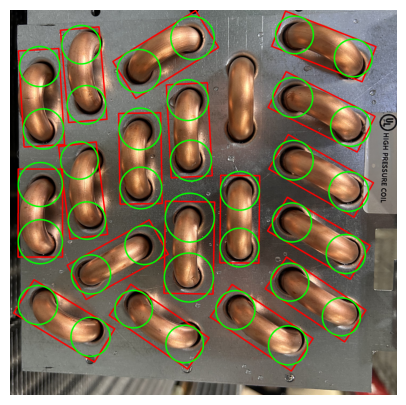

In [34]:

#Read the image using cv2 library
image = cv2.imread(image_path)
#convert that image using color
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

#Create an empty array for the cv2 circles on the coil
circles = []

#using a ranged for loop so I can keep track of the index(lists are 0 indexing)
for i in range(1, len(predictions) + 1):

    #Access the prediciton (lists 0 indexing)
    pred = predictions[i-1]

    #create variables from prediction list (xywhr format)
    x_center, y_center, width, height, angle = pred

    #find the angle of rotation from the rotation value(it is in radians)
    angle_degrees = angle * 180 / np.pi
    
    #create a rect + boxpoints variable which holds the cv2 polylines coordinate for the rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)

    #convert all to ints because measurement it pixel based (cant have fractional pixels)
    box_points = np.int0(box_points)

    #add the prediction boxes to the image (red boxes)
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=10)

    #from info provided by prediction and some math find the offset for the circle coordinates
    add_circles1 = [int(x_center + (np.cos(angle) * ((width * .65) / 2))), 
                    int(y_center + (np.sin(angle) * ((width * .65) / 2))), int(height / 2), i]
    add_circles2 = [int(x_center - (np.cos(angle) * ((width * .65) / 2))), 
                    int(y_center - (np.sin(angle) * ((width * .65) / 2))), int(height / 2), i]
    
    #add the circles to the image
    cv2.circle(image, (add_circles1[0], 
                       add_circles1[1]), add_circles1[2], (0, 255, 0), thickness=10)
    cv2.circle(image, (add_circles2[0], 
                       add_circles2[1]), add_circles2[2], (0, 255, 0), thickness=10)
    
    #append the circles to the circles list so we can use pandas for data analysis
    circles.append(add_circles1)
    circles.append(add_circles2)

#show the figure
plt.figure(figsize=(5,5))
plt.imshow(image)
plt.axis("off")
plt.show()


# Run some analysis on the coordinates

In [35]:
#Save the coordinates as a pandas dataframe for ease of use
coordinates = pd.DataFrame(circles, columns=['X', 'Y', 'Radius', 'return_bend'])

In [36]:
#Create divisions, which are used to seperate bounding box coordinates into their respective circuitry X & Y coordinates
divisions = (coordinates['X'].max() - coordinates['X'].min())/x_rows

# Visualize the results - showing grid layout

In [37]:
"""
x_groups and y_groups are a measurement used to classify where a set of coordinates are relative to their grid lines.
They care calculated by taking the maximum and minimum x and y coordinates and subtracting them from each other (m_max - x_min)
which results in the total space between recognized features. Because coils have rows and columns these measurements should be either
recieved by the model, (x_rows = coils_rows) (y_rows = fin height - single_progression_extrusion). These values are then subtracted
by one in order 
"""

x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .45

y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .45

print(x_groups)
print(y_groups)

392.5
232.4


length of circles array: 36


/var/folders/4p/00p49d_90_3dmt536pgzqb9w0000gn/T/ipykernel_1334/1805079517.py:18: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)


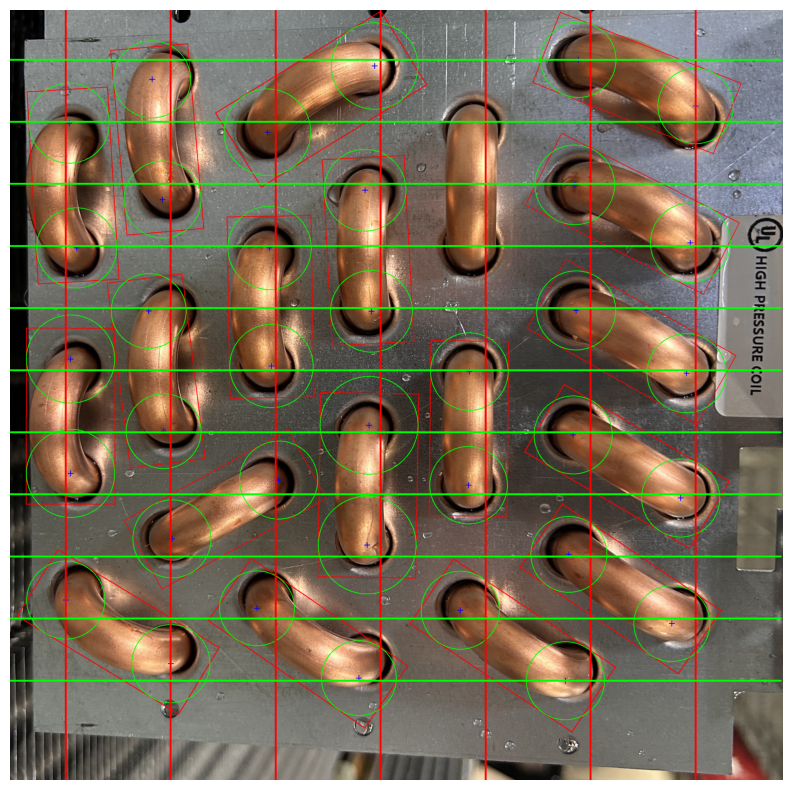

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi

    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)

    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


for circle in circles:
    cv2.line(image, (circle[0], circle[1]-10), (circle[0], circle[1]+10), color=(0, 0, 255), thickness = 2)
    cv2.line(image, (circle[0]-10, circle[1]), (circle[0]+10, circle[1]), color=(0, 0, 255), thickness = 2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=5)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=5)

print(f'length of circles array: {len(circles)}')
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [39]:
"""x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .45

y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .45

print(x_groups)
print(y_groups)"""

"x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)\nx_inter_group_space = x_groups * .45\n\ny_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)\ny_inter_group_space = y_groups * .45\n\nprint(x_groups)\nprint(y_groups)"

In [40]:
"""import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi

    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)

    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))
    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


for circle in circles:
    cv2.line(image, (circle[0], circle[1] - 10), (circle[0], circle[1] + 10), color=(0, 0, 255), thickness=2)
    cv2.line(image, (circle[0] - 10, circle[1]), (circle[0] + 10, circle[1]), color=(0, 0, 255), thickness=2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=2)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=2)

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()"""


'import cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom PIL import Image\n\nimage = cv2.imread(image_path)\nif image is None:\n    raise ValueError("Image not loaded. Check the image path.")\nimage = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)\n\nfor pred in predictions:\n    x_center, y_center, width, height, angle = pred\n    angle_degrees = angle * 180 / np.pi\n\n    rect = ((x_center, y_center), (width, height), angle_degrees)\n\n    box_points = cv2.boxPoints(rect)\n    box_points = np.int0(box_points)\n\n    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)\n\n    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))\n    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))\n    radius = int(height / 2)\n    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)\n    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)\n\n\nfor circle in circles:\n    c

In [41]:

x_group_list=[]
for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    x_group_list.append((y_coord - x_inter_group_space, y_coord + x_inter_group_space))

y_group_list=[]
for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    y_group_list.append((x_coord - y_inter_group_space, x_coord + y_inter_group_space))
    

In [42]:

def assign_group_x(x):
    for i, (min_val, max_val) in enumerate(x_group_list):
        if min_val <= x < max_val:
            return i
    return len(x_group_list)

def assign_group_y(y):
    for i, (min_val, max_val) in enumerate(y_group_list):
        if min_val <= y < max_val:
            return i
    return len(y_group_list)


In [43]:

coordinates['Group_X'] = coordinates['X'].apply(assign_group_x)
coordinates['Group_Y'] = coordinates['Y'].apply(assign_group_y)

In [44]:
grouped = coordinates.groupby('return_bend')[['Group_X', 'Group_Y']]

result = '{' + ','.join(
    '{{{}}}'.format(
        ','.join('{{{},{}}}'.format(row['Group_X']+ 1, row['Group_Y'] + 1) for _, row in group.iterrows())
    )
    for _, group in grouped
) + '}'

print(result)


{{{7,10},{6,9}},{{7,8},{6,7}},{{7,6},{6,5}},{{2,9},{3,8}},{{7,4},{6,3}},{{6,11},{5,10}},{{4,11},{3,10}},{{2,3},{2,1}},{{2,7},{2,5}},{{4,9},{4,7}},{{3,6},{3,4}},{{3,2},{4,1}},{{1,8},{1,6}},{{2,11},{1,10}},{{5,8},{5,6}},{{7,2},{6,1}},{{4,5},{4,3}},{{1,4},{1,2}}}


In [45]:
print(pattern_3_circuitry_string == result)

False


In [46]:
import ast

transformed_result = result.replace('{', '[').replace('}', ']')
transformed_input = pattern_3_circuitry_string.replace('{', '[').replace('}', ']')

list_of_lists_result = ast.literal_eval(transformed_result)
list_of_lists_input = ast.literal_eval(transformed_input)

#print(list_of_lists_result == list_of_lists_input)
print(list_of_lists_result)


[[[7, 10], [6, 9]], [[7, 8], [6, 7]], [[7, 6], [6, 5]], [[2, 9], [3, 8]], [[7, 4], [6, 3]], [[6, 11], [5, 10]], [[4, 11], [3, 10]], [[2, 3], [2, 1]], [[2, 7], [2, 5]], [[4, 9], [4, 7]], [[3, 6], [3, 4]], [[3, 2], [4, 1]], [[1, 8], [1, 6]], [[2, 11], [1, 10]], [[5, 8], [5, 6]], [[7, 2], [6, 1]], [[4, 5], [4, 3]], [[1, 4], [1, 2]]]


In [47]:
print(coordinates.sort_values(by='return_bend'))

       X     Y  Radius  return_bend  Group_X  Group_Y
0   2474  2296     142            1        6        9
1   2089  2037     142            1        5        8
2   2507  1826     146            2        6        7
3   2105  1590     146            2        5        6
4   2529  1359     148            3        6        5
5   2116  1124     148            3        5        4
6    605  1979     146            4        1        8
7   1004  1759     146            4        2        7
8   2543   871     149            5        6        3
9   2111   654     149            5        5        2
10  2076  2510     146            6        5       10
11  1683  2246     146            6        4        9
12  1304  2500     140            7        3       10
13   923  2239     140            7        2        9
14   570   709     144            8        1        2
15   531   259     144            8        1        0
17   518  1126     140            9        1        4
16   574  1576     140      

In [48]:
radius = coordinates['Radius'].mean()

In [49]:
pattern_coordinates = coordinates.drop(labels=['Radius', 'return_bend'], axis=1)

In [50]:
print(pattern_coordinates)

       X     Y  Group_X  Group_Y
0   2474  2296        6        9
1   2089  2037        5        8
2   2507  1826        6        7
3   2105  1590        5        6
4   2529  1359        6        5
5   2116  1124        5        4
6    605  1979        1        8
7   1004  1759        2        7
8   2543   871        6        3
9   2111   654        5        2
10  2076  2510        5       10
11  1683  2246        4        9
12  1304  2500        3       10
13   923  2239        2        9
14   570   709        1        2
15   531   259        1        0
16   574  1576        1        6
17   518  1126        1        4
18  1335  2002        3        8
19  1342  1554        3        6
20   977  1332        2        5
21   970   890        2        3
22   962   457        2        1
23  1363   209        3        0
24   226  1734        0        7
25   226  1306        0        5
26   601  2446        1       10
27   208  2208        0        9
28  1714  1778        4        7
29  1717  

In [51]:
def compare_lists(result_list, input_list):
    correct_return_bends = []
    incorrect_return_bends = []
    not_found_return_bends = []

    result_list_sorted = [sorted(map(tuple, sublist)) for sublist in result_list]
    input_list_sorted = [sorted(map(tuple, sublist)) for sublist in input_list]
    matched_input = set()

    for res in result_list_sorted:
        if res in input_list_sorted:
            correct_return_bends.append(res)
            matched_input.add(tuple(map(tuple, res)))
        else:
            incorrect_return_bends.append(res)

    for inp in input_list_sorted:
        if tuple(map(tuple, inp)) not in matched_input:
            not_found_return_bends.append(inp)

    return correct_return_bends, incorrect_return_bends, not_found_return_bends

correct, incorrect, not_found = compare_lists(list_of_lists_result, list_of_lists_input)

print("Correct Return Bends:", correct)
print("Incorrect Return Bends:", incorrect)
print("Not Found Return Bends:", not_found)

results_array = [(correct, (100, 100, 255)), (incorrect, (255, 0, 0)), (not_found, (255,255,0))]


Correct Return Bends: [[(2, 1), (2, 3)], [(2, 5), (2, 7)], [(3, 2), (4, 1)], [(1, 6), (1, 8)], [(1, 2), (1, 4)]]
Incorrect Return Bends: [[(6, 9), (7, 10)], [(6, 7), (7, 8)], [(6, 5), (7, 6)], [(2, 9), (3, 8)], [(6, 3), (7, 4)], [(5, 10), (6, 11)], [(3, 10), (4, 11)], [(4, 7), (4, 9)], [(3, 4), (3, 6)], [(1, 10), (2, 11)], [(5, 6), (5, 8)], [(6, 1), (7, 2)], [(4, 3), (4, 5)]]
Not Found Return Bends: [[(4, 7), (5, 8)], [(3, 4), (4, 5)], [(4, 3), (5, 2)], [(3, 6), (3, 8)], [(5, 4), (5, 6)]]


In [52]:
#Test to see how to filter column values in pandas
filtered_df = pattern_coordinates[(pattern_coordinates['Group_X'] == 4) & (pattern_coordinates['Group_Y'] == 3)]

x_values = filtered_df['X'].tolist()
y_values = filtered_df['Y'].tolist()

print("X values:", x_values)
print("Y values:", y_values)

X values: []
Y values: []


In [53]:
pattern_coordinates['Group_X'] = pattern_coordinates['Group_X'] + 1
pattern_coordinates['Group_Y'] = pattern_coordinates['Group_Y'] + 1



In [58]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
image_other = cv2.imread(image_path2)
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
if image_other is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_other = cv2.cvtColor(image_other, cv2.COLOR_BGR2RGB)

print(results_array)

for result in results_array:
    for res in result[0]:
        pattern_1_x = res[0][0]
        pattern_1_y = res[0][1]
        pattern_2_x = res[1][0]
        pattern_2_y = res[1][1]

        filtered_df_1 = pattern_coordinates[(pattern_coordinates['Group_X'] == pattern_1_x) & (pattern_coordinates['Group_Y'] == pattern_1_y)]
        filtered_df_2 = pattern_coordinates[(pattern_coordinates['Group_X'] == pattern_2_x) & (pattern_coordinates['Group_Y'] == pattern_2_y)]
        x_values_1 = int(filtered_df_1['X'].values[0])
        y_values_1 = int(filtered_df_1['Y'].values[0])
        x_values_2 = int(filtered_df_2['X'].values[0])
        y_values_2 = int(filtered_df_2['Y'].values[0])

        cv2.line(image, (x_values_1, y_values_1), (x_values_2, y_values_2), color=result[1], thickness=int(radius-50))

fig, axs = plt.subplots(1, 2, figsize=(10, 12))

# Show the first image
axs[0].imshow(image)
axs[0].axis("off")

# Show the second image
axs[1].imshow(image_other)
axs[1].axis("off")

# Display the images
plt.show()



[([[(2, 1), (2, 3)], [(2, 5), (2, 7)], [(3, 2), (4, 1)], [(1, 6), (1, 8)], [(1, 2), (1, 4)]], (100, 100, 255)), ([[(6, 9), (7, 10)], [(6, 7), (7, 8)], [(6, 5), (7, 6)], [(2, 9), (3, 8)], [(6, 3), (7, 4)], [(5, 10), (6, 11)], [(3, 10), (4, 11)], [(4, 7), (4, 9)], [(3, 4), (3, 6)], [(1, 10), (2, 11)], [(5, 6), (5, 8)], [(6, 1), (7, 2)], [(4, 3), (4, 5)]], (255, 0, 0)), ([[(4, 7), (5, 8)], [(3, 4), (4, 5)], [(4, 3), (5, 2)], [(3, 6), (3, 8)], [(5, 4), (5, 6)]], (255, 255, 0))]


IndexError: index 0 is out of bounds for axis 0 with size 0